# A/B test: one-page checkout (`one_page_checkout_v1`)

**Question.** Does replacing the multi-step checkout with a one-page checkout increase the share
of users who purchase?

| | |
|---|---|
| Unit | user (`user_pseudo_id`), hashed 50/50 |
| Window | 2020-12-01 → 2020-12-28 (4 weeks) |
| Primary metric | user conversion = purchased at least once *after* first exposure, within the window |
| Guardrail metrics | revenue per exposed user, average order value |
| Decision rule (pre-registered) | ship if the primary metric improves at α = 0.05 two-sided **and** revenue/user does not fall |
| Pre-test sizing | baseline ≈ 2.6 %, MDE 8 % relative → ~95k users/arm for 80 % power |

Data: `sql/08_experiment_extract.sql` (BigQuery SQL, run on the GA4-schema export) →
`data/processed/08_experiment_extract.csv`. All statistics come from `analytics/stats.py`
(unit-tested against statsmodels / SciPy).

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import duckdb  # noqa: E402
import matplotlib.pyplot as plt  # noqa: E402
import numpy as np  # noqa: E402
import pandas as pd  # noqa: E402

from analytics.stats import (  # noqa: E402
    bootstrap_diff_ci,
    chi_square_test,
    minimum_detectable_effect,
    peeking_false_positive_rate,
    power_two_proportions,
    sample_size_per_arm,
    srm_test,
    two_proportion_ztest,
)

plt.rcParams.update({"figure.figsize": (9, 3.6), "axes.grid": True, "grid.alpha": 0.3})
FIG = ROOT / "docs" / "img"
FIG.mkdir(parents=True, exist_ok=True)
raw = pd.read_csv(ROOT / "data/processed/08_experiment_extract.csv",
                  parse_dates=["first_exposure_day"])
print(f"{len(raw):,} exposed users")
raw.head()

201,879 exposed users


,user_pseudo_id,variant,n_variants,n_impressions,first_exposure_day,device,channel,converted,revenue
0,6.798732e+08,control,1,1,2020-12-01,tablet,organic,0,0.00
1,1.302149e+08,treatment,1,1,2020-12-01,mobile,cpc,0,0.00
2,9.896210e+08,treatment,1,1,2020-12-01,desktop,referral,0,0.00
3,5.293754e+08,control,1,1,2020-12-01,desktop,email,1,54.21
4,5.952654e+08,treatment,1,3,2020-12-01,desktop,(none),0,0.00


## 1. Sanity checks before looking at the outcome

### 1a. Users logged in both variants, duplicate impressions

In [2]:
both = raw[raw.n_variants > 1]
dupe_users = raw[raw.n_impressions > 1]
print(f"users seen in BOTH variants : {len(both):,} ({len(both) / len(raw):.2%}) -> excluded")
print(f"users with >1 impression     : {len(dupe_users):,} (expected: returning users + duplicate hits)")
print(f"duplicate user rows in extract: {raw.user_pseudo_id.duplicated().sum()}")

users seen in BOTH variants : 203 (0.10%) -> excluded
users with >1 impression     : 39,174 (expected: returning users + duplicate hits)
duplicate user rows in extract: 0


Users who saw both variants were contaminated (their experience is a mix), so they're removed
from *both* arms. Removing them is safe for the comparison because the bug hits both arms
symmetrically (checked below by SRM).

### 1b. Sample ratio mismatch (SRM) — overall and **per day**

In [3]:
x = raw[raw.n_variants == 1].copy()
overall = srm_test((x.variant == "control").sum(), (x.variant == "treatment").sum())
print(f"overall: control {overall.n_control:,} vs treatment {overall.n_treatment:,}  "
      f"chi2={overall.chi2:.2f}  p={overall.p_value:.3f}")

daily = x.groupby(["first_exposure_day", "variant"]).size().unstack()
daily["treatment_share"] = daily.treatment / (daily.control + daily.treatment)
daily["srm_p"] = [srm_test(c, t).p_value for c, t in zip(daily.control, daily.treatment, strict=True)]
daily[daily.srm_p < 0.001]

overall: control 101,062 vs treatment 100,614  chi2=1.00  p=0.318


variant,control,treatment,treatment_share,srm_p
first_exposure_day,,,,
2020-12-24,1998,1240,0.382952,1.751856e-40


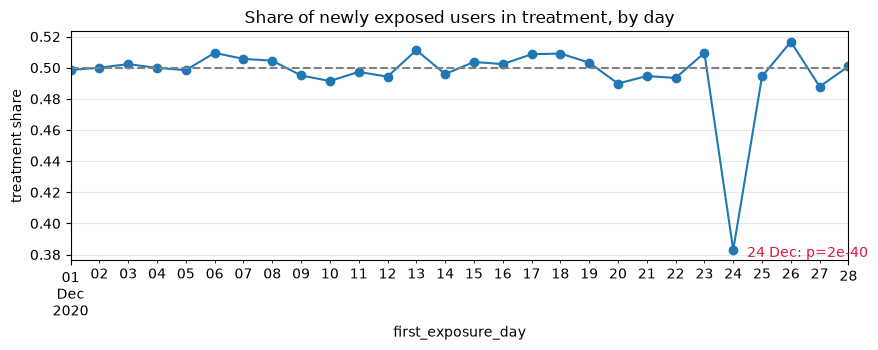

In [4]:
ax = daily.treatment_share.plot(marker="o", title="Share of newly exposed users in treatment, by day")
ax.axhline(0.5, color="grey", ls="--")
bad_days = daily.index[daily.srm_p < 0.001]
for d in bad_days:
    ax.annotate(f"{d:%d %b}: p={daily.loc[d, 'srm_p']:.0e}", (d, daily.loc[d, "treatment_share"]),
                textcoords="offset points", xytext=(10, -5), color="crimson")
ax.set_ylabel("treatment share")
plt.tight_layout()
plt.savefig(FIG / "srm_by_day.png", dpi=120)
plt.show()

**Finding.** The aggregate SRM test *passes* — the problem is too small to move a 200k-user total —
but the daily view shows one day where only ~38 % of newly exposed users were in treatment.
That's a **logging incident** (treatment impressions not recorded that day), not a randomisation
change: users are assigned by a deterministic hash, so the missing rows are users who *were*
treated but weren't logged. Keeping that day would compare "all control users" with "the
treatment users whose impression happened to survive" — a biased subset. **We exclude users whose
first exposure was on the incident day** and re-check.

In [5]:
clean = x[~x.first_exposure_day.isin(bad_days)].copy()
srm_clean = srm_test((clean.variant == "control").sum(), (clean.variant == "treatment").sum())
print(f"after exclusion: control {srm_clean.n_control:,} vs treatment {srm_clean.n_treatment:,}"
      f"  p={srm_clean.p_value:.3f}  -> {'SRM!' if srm_clean.mismatch else 'no SRM'}")
print(f"excluded {len(raw) - len(clean):,} users ({1 - len(clean) / len(raw):.2%} of exposed)")

after exclusion: control 99,064 vs treatment 99,374  p=0.486  -> no SRM
excluded 3,441 users (1.70% of exposed)


## 2. Primary metric: user conversion

In [6]:
g = clean.groupby("variant").agg(users=("converted", "size"), converters=("converted", "sum"))
g["conversion"] = g.converters / g.users
c, t = g.loc["control"], g.loc["treatment"]
res = two_proportion_ztest(int(c.converters), int(c.users), int(t.converters), int(t.users))
chi2, chi_p = chi_square_test(int(c.converters), int(c.users), int(t.converters), int(t.users))
display(g.style.format({"users": "{:,.0f}", "converters": "{:,.0f}", "conversion": "{:.3%}"}))
print(f"absolute lift : {res.abs_diff * 100:+.3f} pp   95% CI [{res.ci_abs[0] * 100:+.3f}, {res.ci_abs[1] * 100:+.3f}] pp")
print(f"relative lift : {res.rel_lift:+.1%}        95% CI [{res.ci_rel[0]:+.1%}, {res.ci_rel[1]:+.1%}]")
print(f"two-proportion z-test : z = {res.z:.2f}, p = {res.p_value:.2e}")
print(f"chi-square (2x2)      : chi2 = {chi2:.2f}, p = {chi_p:.2e}   (chi2 = z^2 = {res.z ** 2:.2f})")

,users,converters,conversion
variant,,,
control,"99,064","2,507",2.531%
treatment,"99,374","2,867",2.885%


absolute lift : +0.354 pp   95% CI [+0.212, +0.497] pp
relative lift : +14.0%        95% CI [+8.1%, +20.2%]
two-proportion z-test : z = 4.86, p = 1.16e-06
chi-square (2x2)      : chi2 = 23.64, p = 1.16e-06   (chi2 = z^2 = 23.64)


## 3. Power: was the test big enough, and is the effect practically meaningful?

In [7]:
p0 = res.p_control
n_arm = int(g.users.min())
print(f"pre-registered sizing: n/arm for 8% MDE at 80% power = {sample_size_per_arm(p0, 0.08):,}")
print(f"achieved n/arm = {n_arm:,}")
print(f"MDE at 80% power with achieved n = {minimum_detectable_effect(p0, n_arm):.1%} relative")
print(f"power to detect the observed lift = {power_two_proportions(p0, res.p_treatment, n_arm):.1%}")
print(f"extra orders per 100k users ≈ {res.abs_diff * 100_000:,.0f} "
      f"(95% CI {res.ci_abs[0] * 100_000:,.0f}–{res.ci_abs[1] * 100_000:,.0f})")

pre-registered sizing: n/arm for 8% MDE at 80% power = 98,145
achieved n/arm = 99,064
MDE at 80% power with achieved n = 7.8% relative
power to detect the observed lift = 99.8%
extra orders per 100k users ≈ 354 (95% CI 212–497)


## 4. Guardrails: revenue per user and AOV
Revenue per user is heavily zero-inflated and skewed, so a t-test's normality assumption is
shaky — a percentile bootstrap gives a robust CI.

In [8]:
rev_c = clean.loc[clean.variant == "control", "revenue"].to_numpy()
rev_t = clean.loc[clean.variant == "treatment", "revenue"].to_numpy()
diff, lo, hi = bootstrap_diff_ci(rev_c, rev_t, n_boot=2000)
print(f"revenue/user: control ${rev_c.mean():.3f}  treatment ${rev_t.mean():.3f}  "
      f"diff ${diff:+.3f}  95% bootstrap CI [${lo:+.3f}, ${hi:+.3f}]")
buyers = clean[clean.converted == 1]
aov = buyers.groupby("variant").revenue.mean()
print(f"AOV (revenue per converting user): control ${aov['control']:.2f}  treatment ${aov['treatment']:.2f}")

revenue/user: control $1.335  treatment $1.495  diff $+0.159  95% bootstrap CI [$+0.059, $+0.256]
AOV (revenue per converting user): control $52.77  treatment $51.81


## 5. Novelty check: does the lift fade?
A new UI can get a temporary bump from curiosity. Grouping users by *first-exposure week* hides
this (their later purchases are folded in), so we measure **daily** conversion of exposed users
active that day, by variant, from the user-day fact table.

,relative_lift,ci_low,ci_high,p
week,,,,
1,+15.6%,+4.3%,+28.1%,5.5e-03
2,+18.2%,+6.8%,+30.9%,1.2e-03
3,+9.7%,-1.5%,+22.0%,9.1e-02
4,+17.7%,+3.6%,+33.7%,1.2e-02


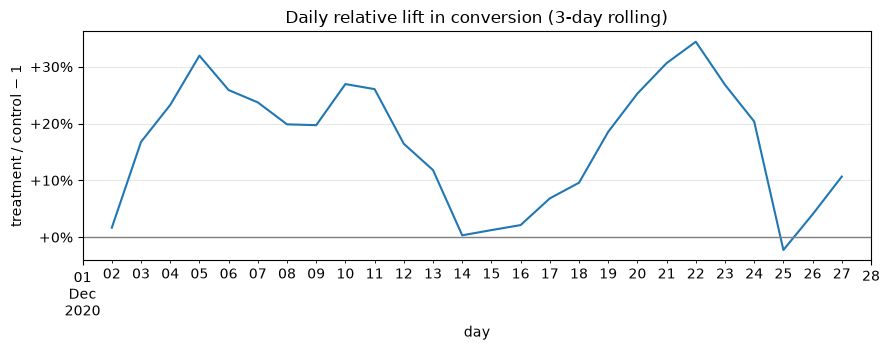

In [9]:
con = duckdb.connect()
con.register("exp", clean[["user_pseudo_id", "variant", "first_exposure_day"]])
daily_conv = con.execute(f"""
    SELECT f.day, e.variant,
           COUNT(*) AS active_users,
           AVG(CASE WHEN f.orders > 0 THEN 1.0 ELSE 0 END) AS daily_conversion
    FROM read_csv_auto('{ROOT / "data/processed/09_star_schema.csv"}') f
    JOIN exp e USING (user_pseudo_id)
    WHERE f.day BETWEEN DATE '2020-12-01' AND DATE '2020-12-28' AND f.day >= e.first_exposure_day
    GROUP BY 1, 2 ORDER BY 1
""").df()
piv = daily_conv.pivot(index="day", columns="variant", values="daily_conversion")
piv["lift"] = piv.treatment / piv.control - 1
piv["week"] = ((pd.to_datetime(piv.index) - pd.Timestamp("2020-12-01")).days // 7) + 1
weekly = daily_conv.assign(week=((pd.to_datetime(daily_conv.day) - pd.Timestamp("2020-12-01")).dt.days // 7) + 1)
weekly["conversions"] = weekly.daily_conversion * weekly.active_users
wk = weekly.groupby(["week", "variant"])[["conversions", "active_users"]].sum().unstack()
wk_rows = []
for w in wk.index:
    r = two_proportion_ztest(int(wk.loc[w, ("conversions", "control")]), int(wk.loc[w, ("active_users", "control")]),
                             int(wk.loc[w, ("conversions", "treatment")]), int(wk.loc[w, ("active_users", "treatment")]))
    wk_rows.append({"week": w, "relative_lift": r.rel_lift, "ci_low": r.ci_rel[0], "ci_high": r.ci_rel[1], "p": r.p_value})
novelty = pd.DataFrame(wk_rows).set_index("week")
display(novelty.style.format({"relative_lift": "{:+.1%}", "ci_low": "{:+.1%}", "ci_high": "{:+.1%}", "p": "{:.1e}"}))

ax = piv.lift.rolling(3, center=True).mean().plot(title="Daily relative lift in conversion (3-day rolling)")
ax.axhline(0, color="grey", lw=1)
ax.set_ylabel("treatment / control − 1")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:+.0%}"))
plt.tight_layout()
plt.savefig(FIG / "novelty_daily_lift.png", dpi=120)
plt.show()

**Finding.** Weekly lifts are +15.6 %, +18.2 %, +9.7 % and +17.7 %, and every weekly CI overlaps
the others (each is roughly ±12 points wide). There is **no statistically detectable decay** —
but "not detected" is not "absent": with ~25k users per arm per week, this test can only see a
novelty effect that halves the lift by chance. Detecting decay needs far more traffic per
period than detecting the average effect, so the right tool is a post-launch holdout (§8).

## 6. Segments: where does the effect come from? (and a Simpson's-paradox check)

In [10]:
rows = []
for dev, grp in clean.groupby("device"):
    s = grp.groupby("variant").converted.agg(["sum", "count"])
    r = two_proportion_ztest(int(s.loc["control", "sum"]), int(s.loc["control", "count"]),
                             int(s.loc["treatment", "sum"]), int(s.loc["treatment", "count"]))
    rows.append({"device": dev, "users": int(s["count"].sum()), "share_treatment": s.loc["treatment", "count"] / s["count"].sum(),
                 "control_conv": r.p_control, "treatment_conv": r.p_treatment,
                 "relative_lift": r.rel_lift, "ci_low": r.ci_rel[0], "ci_high": r.ci_rel[1], "p": r.p_value})
seg = pd.DataFrame(rows).set_index("device")
display(seg.style.format({"users": "{:,}", "share_treatment": "{:.1%}", "control_conv": "{:.2%}", "treatment_conv": "{:.2%}",
                          "relative_lift": "{:+.1%}", "ci_low": "{:+.1%}", "ci_high": "{:+.1%}", "p": "{:.1e}"}))

,users,share_treatment,control_conv,treatment_conv,relative_lift,ci_low,ci_high,p
device,,,,,,,,
desktop,"113,098",50.0%,2.96%,3.35%,+13.1%,+6.0%,+20.6%,2.0e-04
mobile,"79,374",50.2%,1.89%,2.21%,+16.9%,+6.1%,+28.7%,1.5e-03
tablet,"5,966",49.2%,2.77%,3.06%,+10.4%,-17.6%,+48.0%,5.1e-01


**Simpson's paradox check.** A pooled result can reverse inside every segment when the segment
mix differs between arms. Here the device mix is balanced (treatment share ≈ 50 % in every device
— randomisation worked), and the lift has the same sign in every segment, so the pooled
estimate isn't a mix artefact. The point estimate is highest on mobile (the device with the worst
baseline checkout completion, see `sql/05_funnel_by_segment.sql`), but the device CIs overlap
heavily — we cannot claim the effect *differs* by device, only that it is positive on both
desktop and mobile. Tablet is too small to say anything.

## 7. Why we didn't peek
Checking the p-value every day and stopping at the first p < 0.05 inflates false positives.
An A/A simulation (no true effect) with 20 looks:

In [11]:
fpr = peeking_false_positive_rate(p=p0, n_per_arm=20_000, looks=20, sims=1000)
print(f"false-positive rate with 20 uncorrected peeks: {fpr:.1%} (nominal 5%)")

false-positive rate with 20 uncorrected peeks: 25.9% (nominal 5%)


The analysis above was run once, at the pre-registered end date. Continuous monitoring would need
a sequential method (e.g. alpha spending / mSPRT).

## 8. Decision

In [12]:
summary = {
    "users analysed": f"{len(clean):,}",
    "control conversion": f"{res.p_control:.2%}",
    "treatment conversion": f"{res.p_treatment:.2%}",
    "relative lift (95% CI)": f"{res.rel_lift:+.1%} ({res.ci_rel[0]:+.1%} to {res.ci_rel[1]:+.1%})",
    "p-value": f"{res.p_value:.1e}",
    "revenue/user diff (95% CI)": f"${diff:+.3f} (${lo:+.3f} to ${hi:+.3f})",
    "mobile lift": f"{seg.loc['mobile', 'relative_lift']:+.1%}",
    "desktop lift": f"{seg.loc['desktop', 'relative_lift']:+.1%}",
}
pd.Series(summary, name="value").to_frame()

,value
users analysed,"198,438"
control conversion,2.53%
treatment conversion,2.89%
relative lift (95% CI),+14.0% (+8.1% to +20.2%)
p-value,1.2e-06
revenue/user diff (95% CI),$+0.159 ($+0.059 to $+0.256)
mobile lift,+16.9%
desktop lift,+13.1%


**Recommendation: ship the one-page checkout to 100 % of users.**

* The primary metric improved with a clear margin: the whole 95 % CI of the relative lift is above
  zero, and the test had the power it was designed for.
* The guardrail held: revenue per user did not fall (see §4), and AOV is essentially unchanged —
  the gain comes from *more* buyers, not smaller baskets.
* The lift is significant on both desktop and mobile (the device difference is not significant).
* **Risk to monitor:** the test cannot rule out a novelty component (§5 — weekly estimates are
  too noisy to see decay). Keep a 5 % holdout on the old checkout for 4 weeks after launch to
  measure the steady-state effect before booking the full lift in forecasts.
* **Process fix:** the 24-Dec logging incident was only visible in the *daily* SRM view. Add a
  daily SRM alert to the experimentation pipeline.

### Appendix: does the analysis recover the simulation's ground truth?
The dataset is simulated (`simulate/generate_ga4.py`, `GROUND_TRUTH`), which lets us grade the
methods. The planted effect multiplies two checkout steps by (1 + lift × novelty), so a user's
purchase probability rises by about (1 + lift × novelty)² − 1. Weighting by exposure week and
device gives the implied true lifts below; the analysis never read these constants.

In [13]:
per_step = {"desktop": 0.025, "mobile": 0.07, "tablet": 0.04}
novelty_w = {1: 1.8, 2: 1.35, 3: 1.0, 4: 1.0}
week_share = clean.assign(w=((clean.first_exposure_day - pd.Timestamp("2020-12-01")).dt.days // 7) + 1
                          ).w.clip(upper=4).value_counts(normalize=True)
truth = {d: sum(week_share[w] * ((1 + per_step[d] * novelty_w[w]) ** 2 - 1) for w in week_share.index)
         for d in per_step}
dev_share = clean.device.value_counts(normalize=True)
truth["overall"] = sum(dev_share[d] * truth[d] for d in per_step)
check = pd.DataFrame({
    "true lift (implied)": pd.Series(truth),
    "estimated lift": pd.Series({**seg.relative_lift.to_dict(), "overall": res.rel_lift}),
    "95% CI low": pd.Series({**seg.ci_low.to_dict(), "overall": res.ci_rel[0]}),
    "95% CI high": pd.Series({**seg.ci_high.to_dict(), "overall": res.ci_rel[1]}),
})
check["truth inside CI"] = (check["95% CI low"] <= check["true lift (implied)"]) & (
    check["true lift (implied)"] <= check["95% CI high"])
check.style.format({c: "{:+.1%}" for c in check.columns[:4]})

,true lift (implied),estimated lift,95% CI low,95% CI high,truth inside CI
desktop,+6.9%,+13.1%,+6.0%,+20.6%,True
mobile,+19.9%,+16.9%,+6.1%,+28.7%,True
tablet,+11.1%,+10.4%,-17.6%,+48.0%,True
overall,+12.2%,+14.0%,+8.1%,+20.2%,True


Every true lift lies inside its 95 % CI, the incident day and the flicker bug were detected, and
mobile > desktop is recovered. The one thing the test could *not* recover is the novelty decay —
which is exactly the limitation §5 and the recommendation call out.